# Field Shift · Experiment v2 — why the intervals failed, and adaptive intervals

**Nothing from Phases 1–3 is modified.** The point models stay the tested v1 models (`artifacts/final_model/`); this
notebook writes only to `artifacts/v2_intervals_experiment/`.

1. Diagnosis: overfitting, or intervals that ignore how hard a month is?
2. Fix that needs no new data: **conformalized quantile regression (CQR)** (Romano et al., 2019). Two quantile XGBoost
   models (5 % and 95 %) learn from 1998–2017, which includes the El Niño years 1998 and 2017, *when* errors grow; the
   interval then widens in extreme months instead of having one width per season. Calibration on Validation 2018–2022.
3. Check on 2023–2025. **Caveat:** those years were already used by the Phase 3 test, so this is a second look, not an
   independent test. The independent confirmation is 2026 once its data are complete.

## 1. Setup

In [1]:
import sys, json, math, platform, time
from pathlib import Path
import numpy as np, pandas as pd, xgboost as xgb
import matplotlib.pyplot as plt
ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from fs_ml import data as D, features as F, evaluate as E
from fs_ml.predict import load, predict, season_of

SEED = 42
pd.set_option("display.width", 170, "display.max_columns", 30)
SPLITS = {"training": (1998, 2017), "validation": (2018, 2022), "testing": (2023, 2025)}
INTERNAL = {"fit": (1998, 2015), "early_stopping": (2016, 2017)}
NOMINAL = 0.90
ART = ML_DIR / "artifacts" / "v2_intervals_experiment"; ART.mkdir(parents=True, exist_ok=True)
NAMES = ["sm_root_monthly", "ndvi_quarterly"]
V1 = {n: load(n) for n in NAMES}
print({n: V1[n]["card"]["sha256"][:16] for n in NAMES}, "| xgboost", xgb.__version__)

{'sm_root_monthly': 'a4bbaf1397c43e2c', 'ndvi_quarterly': 'effe57ea2506d509'} | xgboost 3.4.1


## 2. Tables for the three periods (same `fs_ml` code as every phase)

In [2]:
def build(load_years, suffix):
    monthly, _ = D.load_gee_monthly(load_years); veg, _ = D.load_gee_quarterly(load_years)
    pw = {p: D.load_power(f"power_{p}{suffix}", load_years)[0] for p in ["t2m", "rh2m", "ws2m", "allsky"]}
    merra = pw["t2m"].merge(pw["rh2m"], on=["power_lat", "power_lon", "date"]).merge(pw["ws2m"], on=["power_lat", "power_lon", "date"])
    gaez = {k: D.load_gaez(k)[0] for k in F.GAEZ_FEATURES}
    cells = F.static_cells(D.cells_from_ids(monthly.cell_id), gaez, merra[["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True),
                           pw["allsky"][["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True))
    mp = F.build_monthly_panel(monthly, cells, merra, pw["allsky"]); qp = F.build_quarterly_panel(mp, veg)
    blk = pd.Series(E.spatial_blocks(cells.lat, cells.lon), index=cells.cell_id)
    for df in (mp, qp): df["block"] = df.cell_id.map(blk)
    return {"sm_root_monthly": mp, "ndvi_quarterly": qp}

T = {"training": build((1998, 2017), ""), "validation": build((2017, 2022), "_2018_2022"), "testing": build((2022, 2025), "_2023_2025")}
def rows(period, name):
    df = T[period][name]; t = V1[name]["card"]["target"]["column"]
    return df[df.year.between(*SPLITS[period]) & df[t].notna()].reset_index(drop=True)
R = {p: {n: rows(p, n) for n in NAMES} for p in SPLITS}
print({p: {n: len(R[p][n]) for n in NAMES} for p in SPLITS})

{'training': {'sm_root_monthly': 750240, 'ndvi_quarterly': 91224}, 'validation': {'sm_root_monthly': 187560, 'ndvi_quarterly': 50477}, 'testing': {'sm_root_monthly': 112536, 'ndvi_quarterly': 30056}}


## 3. Diagnosis

### 3.1 Overfitting? Error of the same v1 model in each period

In [3]:
diag = []
for n in NAMES:
    t = V1[n]["card"]["target"]["column"]
    for p in SPLITS:
        r = R[p][n]; pr = V1[n]["model"].predict(r[V1[n]["features"]])
        diag.append({"model": n, "period": p + (" (in-sample)" if p == "training" else ""), **E.regression_metrics(r[t], pr)})
pd.DataFrame(diag).round(4)

,model,period,n,MAE,RMSE,R2,bias
0,sm_root_monthly,training (in-sample),750240,0.0043,0.0071,0.9954,0.0000
1,sm_root_monthly,validation,187560,0.0073,0.0125,0.9860,-0.0004
2,sm_root_monthly,testing,112536,0.0113,0.0198,0.9615,-0.0030
3,ndvi_quarterly,training (in-sample),91224,0.0725,0.1008,0.7333,-0.0000
4,ndvi_quarterly,validation,50477,0.0747,0.1031,0.6624,0.0015
5,ndvi_quarterly,testing,30056,0.0938,0.1262,0.5258,-0.0264


Reading: the in-sample error is 2–3× smaller than on new years (expected optimism of boosted trees), but the error on new
years does **not** keep growing from Validation to Testing beyond what the El Niño explains, and the skill over the simple
rules stays the same in all phases. That is mild overfitting with stable generalization, not the cause of the interval
failure. More regularization would narrow the train/test gap a little; it would not teach the model about El Niño.

### 3.2 The real cause: the error grows with rain, the v1 interval does not

In [4]:
BINS = {"sm_root_monthly": ("rain_mm", [0, 1, 10, 30, 60, 1e9], ["<1 mm", "1-10", "10-30", "30-60", ">60 mm"]),
        "ndvi_quarterly": ("q_rain_mm", [0, 5, 30, 100, 200, 1e9], ["<5 mm", "5-30", "30-100", "100-200", ">200 mm"])}
het = []
for n in NAMES:
    col, edges, labels = BINS[n]; t = V1[n]["card"]["target"]["column"]
    for p in ["validation", "testing"]:
        r = R[p][n]; out = predict(V1[n], r)
        r = r.assign(err=np.abs(out.prediction - r[t]), inside=(r[t] >= out.low) & (r[t] <= out.high),
                     bin=pd.cut(r[col], edges, labels=labels, right=False))
        g = r.groupby("bin", observed=True).agg(rows=("err", "size"), mean_abs_error=("err", "mean"), v1_coverage=("inside", "mean"))
        het.append(g.assign(model=n, period=p).reset_index())
HET = pd.concat(het)[["model", "period", "bin", "rows", "mean_abs_error", "v1_coverage"]]
HET.round(4)

,model,period,bin,rows,mean_abs_error,v1_coverage
0,sm_root_monthly,validation,<1 mm,60433,0.0040,0.9604
1,sm_root_monthly,validation,1-10,59162,0.0054,0.9335
2,sm_root_monthly,validation,10-30,35055,0.0102,0.8347
3,sm_root_monthly,validation,30-60,20190,0.0139,0.7666
4,sm_root_monthly,validation,>60 mm,12720,0.0124,0.8495
0,sm_root_monthly,testing,<1 mm,36071,0.0087,0.8612
1,sm_root_monthly,testing,1-10,33711,0.0092,0.8664
2,sm_root_monthly,testing,10-30,21337,0.0143,0.7130
3,sm_root_monthly,testing,30-60,11453,0.0173,0.7120
4,sm_root_monthly,testing,>60 mm,9964,0.0151,0.8206


## 4. Fix without new data: conformalized quantile regression (CQR)

Rules written before looking at 2023–2025 with v2:
- Same features, hyperparameters, seed and early-stopping protocol as v1; objective `reg:quantileerror` at 5 % and 95 %.
- Two calibration variants: one global correction, or one correction per season (as v1). The variant is chosen **on
  Validation only**: calibrate on 2018–2020, check on 2021–2022; pick the one whose coverage is closest to 90 %, the
  narrower one on a tie (±1 point).
- v2 is worth adopting only if, on 2023–2025, its 90 % coverage lies in [0.87, 0.93] (the same rule F as v1).

In [5]:
V1_PARAMS = V1["sm_root_monthly"]["card"]["hyperparameters"]
QPARAMS = {k: v for k, v in V1_PARAMS.items() if k not in ("objective", "eval_metric", "n_estimators")}
QPARAMS |= {"objective": "reg:quantileerror", "quantile_alpha": np.array([0.05, 0.95]), "n_estimators": 3000, "early_stopping_rounds": 100}

Q = {}
for n in NAMES:
    t = V1[n]["card"]["target"]["column"]; feats = V1[n]["features"]; d = R["training"][n]
    fit, es = d[d.year.between(*INTERNAL["fit"])], d[d.year.between(*INTERNAL["early_stopping"])]
    t0 = time.time()
    m1 = xgb.XGBRegressor(**QPARAMS).fit(fit[feats], fit[t], eval_set=[(es[feats], es[t])], verbose=False)
    best = m1.best_iteration + 1
    p2 = {k: v for k, v in QPARAMS.items() if k != "early_stopping_rounds"} | {"n_estimators": best}
    m2 = xgb.XGBRegressor(**p2).fit(d[feats], d[t], verbose=False)
    Q[n] = {"model": m2, "trees": best, "seconds": round(time.time() - t0, 1)}
    print(n, "| quantile trees:", best, "|", Q[n]["seconds"], "s")

sm_root_monthly | quantile trees: 727 | 68.4 s


ndvi_quarterly | quantile trees: 212 | 2.8 s


In [6]:
def scores(n, period):
    r = R[period][n]; t = V1[n]["card"]["target"]["column"]
    q = Q[n]["model"].predict(r[V1[n]["features"]])
    lo, hi = np.minimum(q[:, 0], q[:, 1]), np.maximum(q[:, 0], q[:, 1])
    return r, r[t].to_numpy(), lo, hi, np.maximum(lo - r[t].to_numpy(), r[t].to_numpy() - hi)

def correction(s, level=NOMINAL):
    s = np.sort(s); k = min(len(s), math.ceil((len(s) + 1) * level)); return float(s[k - 1])

SEL, CAL = [], {}
for n in NAMES:
    r, y, lo, hi, s = scores(n, "validation"); seas = season_of(n, r).to_numpy(); yr = r.year.to_numpy()
    a, b = yr <= 2020, yr >= 2021
    g = correction(s[a]); cov_g = float(((y[b] >= lo[b] - g) & (y[b] <= hi[b] + g)).mean()); w_g = float(np.mean(hi[b] - lo[b] + 2 * g))
    cs = {x: correction(s[a & (seas == x)]) for x in set(seas)}; c = np.array([cs[x] for x in seas])
    cov_s = float(((y[b] >= lo[b] - c[b]) & (y[b] <= hi[b] + c[b])).mean()); w_s = float(np.mean(hi[b] - lo[b] + 2 * c[b]))
    v1 = predict(V1[n], r); cov_v1 = float(((y[b] >= v1.low[b]) & (y[b] <= v1.high[b])).mean()); w_v1 = float(np.mean(v1.high[b] - v1.low[b]))
    SEL += [{"model": n, "variant": "v1 (season width)", "coverage_2021_2022": cov_v1, "mean_width": w_v1},
            {"model": n, "variant": "v2 CQR global", "coverage_2021_2022": cov_g, "mean_width": w_g},
            {"model": n, "variant": "v2 CQR by season", "coverage_2021_2022": cov_s, "mean_width": w_s}]
    gap_g, gap_s = abs(cov_g - NOMINAL), abs(cov_s - NOMINAL)
    choice = "global" if (gap_g < gap_s - 0.01 or (abs(gap_g - gap_s) <= 0.01 and w_g <= w_s)) else "season"
    # final calibration of the chosen variant on all of 2018-2022
    CAL[n] = {"variant": choice, "global": correction(s), "season": {x: correction(s[seas == x]) for x in set(seas)}}
    print(n, "-> chosen on Validation:", choice)
pd.DataFrame(SEL).round(4)

sm_root_monthly -> chosen on Validation: season
ndvi_quarterly -> chosen on Validation: global


,model,variant,coverage_2021_2022,mean_width
0,sm_root_monthly,v1 (season width),0.8854,0.0368
1,sm_root_monthly,v2 CQR global,0.8221,0.0334
2,sm_root_monthly,v2 CQR by season,0.8185,0.0333
3,ndvi_quarterly,v1 (season width),0.8866,0.3304
4,ndvi_quarterly,v2 CQR global,0.8735,0.3366
5,ndvi_quarterly,v2 CQR by season,0.8661,0.3371


## 5. Second look at 2023–2025 (already seen by Phase 3: not an independent test)

In [7]:
def v2_interval(n, period):
    r, y, lo, hi, _ = scores(n, period); c = CAL[n]
    corr = np.full(len(r), c["global"]) if c["variant"] == "global" else season_of(n, r).map(c["season"]).to_numpy(float)
    return r, y, lo - corr, hi + corr

def winkler(y, lo, hi, alpha=1 - NOMINAL):
    # interval score (Gneiting & Raftery, 2007): width + penalty when the truth falls outside; lower is better
    return float(np.mean((hi - lo) + 2 / alpha * (lo - y) * (y < lo) + 2 / alpha * (y - hi) * (y > hi)))

RES, BY = [], []
for n in NAMES:
    r, y, lo2, hi2 = v2_interval(n, "testing"); v1 = predict(V1[n], r); blk = r.block.to_numpy()
    for label, lo, hi in [("v1 (tested)", v1.low.to_numpy(), v1.high.to_numpy()), ("v2 CQR", lo2, hi2)]:
        inside = (y >= lo) & (y <= hi); c, cl, ch = E.coverage_ci(inside, blk)
        RES.append({"model": n, "interval": label, "coverage": c, "ci_low": cl, "ci_high": ch, "mean_width": float(np.mean(hi - lo)),
                    "interval_score": winkler(y, lo, hi), "passes_F": 0.87 <= c <= 0.93})
        groups = {"year": r.year.astype(str), "season": season_of(n, r)}
        col, edges, labels = BINS[n]; groups["rain"] = pd.cut(r[col], edges, labels=labels, right=False).astype(str)
        for gname, gv in groups.items():
            for k in sorted(gv.unique()):
                m = (gv == k).to_numpy()
                BY.append({"model": n, "interval": label, "group": gname, "value": k, "rows": int(m.sum()),
                           "coverage": float(inside[m].mean()), "mean_width": float(np.mean(hi[m] - lo[m]))})
RESULT = pd.DataFrame(RES); RESULT.round(4)

,model,interval,coverage,ci_low,ci_high,mean_width,interval_score,passes_F
0,sm_root_monthly,v1 (tested),0.8159,0.7926,0.8401,0.0368,0.1015,False
1,sm_root_monthly,v2 CQR,0.8231,0.8096,0.8366,0.0394,0.0818,False
2,ndvi_quarterly,v1 (tested),0.8396,0.8264,0.8547,0.3297,0.5616,False
3,ndvi_quarterly,v2 CQR,0.8590,0.8449,0.8733,0.3535,0.5001,False


In [8]:
BYT = pd.DataFrame(BY).pivot_table(index=["model", "group", "value"], columns="interval", values=["coverage", "mean_width"])
BYT.round(3)

coverage         mean_width       
interval                           v1 (tested) v2 CQR v1 (tested) v2 CQR
model           group  value                                            
ndvi_quarterly  rain   100-200           0.825  0.836       0.337  0.380
                       30-100            0.834  0.830       0.333  0.353
                       5-30              0.857  0.890       0.318  0.343
                       <5 mm             0.814  0.836       0.336  0.347
                       >200 mm           0.862  0.866       0.364  0.412
                season Q1                0.864  0.879       0.368  0.384
                       Q2                0.794  0.753       0.406  0.396
                       Q3                0.861  0.902       0.300  0.327
                       Q4                0.842  0.905       0.246  0.308
                year   2023              0.807  0.853       0.330  0.371
                       2024              0.873  0.899       0.330  0.346
                       2025              0.838  0.824       0.330  0.343
sm_root_monthly rain   1-10              0.866  0.805       0.032  0.030
                       10-30             0.713  0.798       0.036  0.047
                       30-60             0.712  0.840       0.043  0.062
                       <1 mm             0.861  0.838       0.035  0.032
                       >60 mm            0.821  0.864       0.052  0.057
                season dry May-Dec       0.840  0.841       0.026  0.030
                       wet Jan-Apr       0.767  0.787       0.059  0.059
                year   2023              0.772  0.780       0.037  0.043
                       2024              0.836  0.814       0.037  0.034
                       2025              0.839  0.875       0.037  0.042

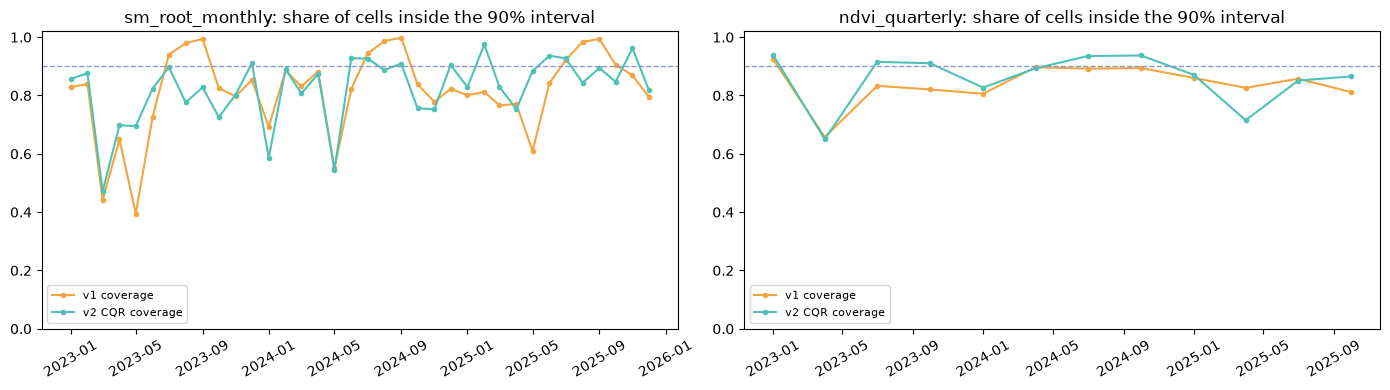

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, n in zip(ax, NAMES):
    r, y, lo2, hi2 = v2_interval(n, "testing"); v1 = predict(V1[n], r)
    if "date" not in r: r = r.assign(date=pd.to_datetime(dict(year=r.year, month=(r.quarter - 1) * 3 + 1, day=1)))
    df = pd.DataFrame({"date": r.date, "y": y, "in1": (y >= v1.low) & (y <= v1.high), "in2": (y >= lo2) & (y <= hi2)})
    g = df.groupby("date")[["in1", "in2"]].mean()
    a.plot(g.index, g.in1, color="#F2A541", marker="o", ms=3, label="v1 coverage")
    a.plot(g.index, g.in2, color="#4FC1B6", marker="o", ms=3, label="v2 CQR coverage")
    a.axhline(0.9, color="#8C9BC4", ls="--", lw=1); a.set_ylim(0, 1.02); a.set_title(f"{n}: share of cells inside the 90% interval")
    a.legend(fontsize=8); a.tick_params(axis="x", labelrotation=30)
plt.tight_layout(); fig.savefig(ART / "v2_coverage.png", dpi=110); plt.show()

## 6. Recalibrate as new months arrive: adaptive conformal inference (ACI)

Diagnosis 3.2 shows the error grew in 2023–2025 even in dry months: conditions drifted away from the past, and no width
fixed in the past can promise 90 % under drift. The standard remedy (Gibbs & Candès, 2021) is to recalibrate with every
new observed month: the width comes from the errors of the last 3 years already observed (36 months / 12 quarters, same
season), and the target level moves up when the last period missed too often (step γ). Only past periods are used at each
step, as the app would do in operation.

γ is chosen **on Validation only** (history 2018–2019, run over 2020–2022): the γ whose coverage is closest to 90 %,
the narrower on a tie (±1 point). The run then continues through 2023–2025.

In [10]:
GAMMAS = [0.0, 0.05, 0.1, 0.2, 0.5]
WINDOW = {"sm_root_monthly": 36, "ndvi_quarterly": 12}

def stream(n, kind):
    # validation + testing rows in time order with their score and the base band (center or quantile band)
    parts = []
    for period in ["validation", "testing"]:
        r, y, lo, hi, s = scores(n, period)
        if kind == "v1":
            pr = V1[n]["model"].predict(r[V1[n]["features"]]); lo, hi, s = pr, pr, np.abs(pr - y)
        key = r.date if "date" in r else pd.to_datetime(dict(year=r.year, month=(r.quarter - 1) * 3 + 1, day=1))
        parts.append(pd.DataFrame({"t": key.values, "season": season_of(n, r).values, "y": y, "lo": lo, "hi": hi, "s": s,
                                   "year": r.year.values, "block": r.block.values}))
    return pd.concat(parts, ignore_index=True)

def run_aci(df, gamma, start, window):
    periods = np.sort(df.t.unique()); alpha = 1 - NOMINAL; out = []
    for i, t in enumerate(periods):
        if t < np.datetime64(start): continue
        past = periods[max(0, i - window):i]
        cur = df[df.t == t]
        lo_o, hi_o = np.empty(len(cur)), np.empty(len(cur))
        for sea, g in cur.groupby("season"):
            hist = df.s[df.t.isin(past) & (df.season == sea)].to_numpy()
            if len(hist) == 0: hist = df.s[df.t.isin(past)].to_numpy()
            level = float(np.clip(1 - alpha, 0.5, 0.999))
            c = float(np.quantile(hist, level, method="higher"))
            idx = cur.index.get_indexer(g.index); lo_o[idx], hi_o[idx] = g.lo - c, g.hi + c
        inside = (cur.y.to_numpy() >= lo_o) & (cur.y.to_numpy() <= hi_o)
        out.append(pd.DataFrame({"t": t, "year": cur.year.values, "season": cur.season.values, "block": cur.block.values,
                                 "y": cur.y.values, "lo": lo_o, "hi": hi_o, "inside": inside}))
        alpha = float(np.clip(alpha + gamma * ((1 - NOMINAL) - (1 - inside.mean())), 0.001, 0.5))
    return pd.concat(out, ignore_index=True)

ACI, GSEL = {}, []
for n in NAMES:
    for kind in ["v1", "cqr"]:
        df = stream(n, kind); best = None
        for g in GAMMAS:
            run = run_aci(df[df.year <= 2022], g, "2020-01-01", WINDOW[n])
            cov, w = float(run.inside.mean()), float((run.hi - run.lo).mean())
            GSEL.append({"model": n, "base": kind, "gamma": g, "coverage_2020_2022": cov, "mean_width": w})
            if best is None or abs(cov - NOMINAL) < abs(best[1] - NOMINAL) - 0.01 or (abs(abs(cov - NOMINAL) - abs(best[1] - NOMINAL)) <= 0.01 and w < best[2]):
                best = (g, cov, w)
        full = run_aci(df, best[0], "2020-01-01", WINDOW[n])
        ACI[(n, kind)] = {"gamma": best[0], "run": full[full.year >= 2023]}
        print(n, kind, "-> gamma chosen on Validation:", best[0])
pd.DataFrame(GSEL).round(4)

sm_root_monthly v1 -> gamma chosen on Validation: 0.1


sm_root_monthly cqr -> gamma chosen on Validation: 0.2


ndvi_quarterly v1 -> gamma chosen on Validation: 0.0


ndvi_quarterly cqr -> gamma chosen on Validation: 0.2


,model,base,gamma,coverage_2020_2022,mean_width
0,sm_root_monthly,v1,0.00,0.8892,0.0350
1,sm_root_monthly,v1,0.05,0.8961,0.0364
2,sm_root_monthly,v1,0.10,0.9003,0.0373
3,sm_root_monthly,v1,0.20,0.9034,0.0383
4,sm_root_monthly,v1,0.50,0.9021,0.0416
5,sm_root_monthly,cqr,0.00,0.8561,0.0332
6,sm_root_monthly,cqr,0.05,0.8882,0.0355
7,sm_root_monthly,cqr,0.10,0.8972,0.0365
8,sm_root_monthly,cqr,0.20,0.8998,0.0383
9,sm_root_monthly,cqr,0.50,0.8961,0.0400


In [11]:
for (n, kind), a in ACI.items():
    run = a["run"]; c, cl, ch = E.coverage_ci(run.inside.to_numpy(), run.block.to_numpy())
    label = ("v1" if kind == "v1" else "v2 CQR") + " + monthly recalibration (ACI)"
    RES.append({"model": n, "interval": label, "coverage": c, "ci_low": cl, "ci_high": ch, "mean_width": float((run.hi - run.lo).mean()),
                "interval_score": winkler(run.y.to_numpy(), run.lo.to_numpy(), run.hi.to_numpy()), "passes_F": 0.87 <= c <= 0.93})
    for gname, gv in {"year": run.year.astype(str), "season": run.season}.items():
        for k in sorted(gv.unique()):
            m = (gv == k).to_numpy()
            BY.append({"model": n, "interval": label, "group": gname, "value": k, "rows": int(m.sum()),
                       "coverage": float(run.inside[m].mean()), "mean_width": float((run.hi - run.lo)[m].mean())})
RESULT = pd.DataFrame(RES); display(RESULT.round(4))
BYT = pd.DataFrame(BY).query("group != 'rain'").pivot_table(index=["model", "group", "value"], columns="interval", values="coverage")
BYT.round(3)

,model,interval,coverage,ci_low,ci_high,mean_width,interval_score,passes_F
0,sm_root_monthly,v1 (tested),0.8159,0.7926,0.8401,0.0368,0.1015,False
1,sm_root_monthly,v2 CQR,0.8231,0.8096,0.8366,0.0394,0.0818,False
2,ndvi_quarterly,v1 (tested),0.8396,0.8264,0.8547,0.3297,0.5616,False
3,ndvi_quarterly,v2 CQR,0.8590,0.8449,0.8733,0.3535,0.5001,False
4,sm_root_monthly,v1 + monthly recalibration (ACI),0.9030,0.8866,0.9196,0.0632,0.0971,True
5,sm_root_monthly,v2 CQR + monthly recalibration (ACI),0.9034,0.8914,0.9146,0.0512,0.0809,True
6,ndvi_quarterly,v1 + monthly recalibration (ACI),0.8693,0.8573,0.8828,0.3645,0.5607,False
7,ndvi_quarterly,v2 CQR + monthly recalibration (ACI),0.8923,0.8809,0.9042,0.3859,0.4923,True


interval                            v1 (tested)  v1 + monthly recalibration (ACI)  v2 CQR  v2 CQR + monthly recalibration (ACI)
model           group  value                                                                                                   
ndvi_quarterly  season Q1                 0.864                             0.865   0.879                                 0.891
                       Q2                 0.794                             0.856   0.753                                 0.853
                       Q3                 0.861                             0.891   0.902                                 0.918
                       Q4                 0.842                             0.865   0.905                                 0.908
                year   2023               0.807                             0.811   0.853                                 0.880
                       2024               0.873                             0.912   0.899                                 0.931
                       2025               0.838                             0.885   0.824                                 0.864
sm_root_monthly season dry May-Dec        0.840                             0.915   0.841                                 0.912
                       wet Jan-Apr        0.767                             0.879   0.787                                 0.886
                year   2023               0.772                             0.870   0.780                                 0.892
                       2024               0.836                             0.913   0.814                                 0.899
                       2025               0.839                             0.926   0.875                                 0.919

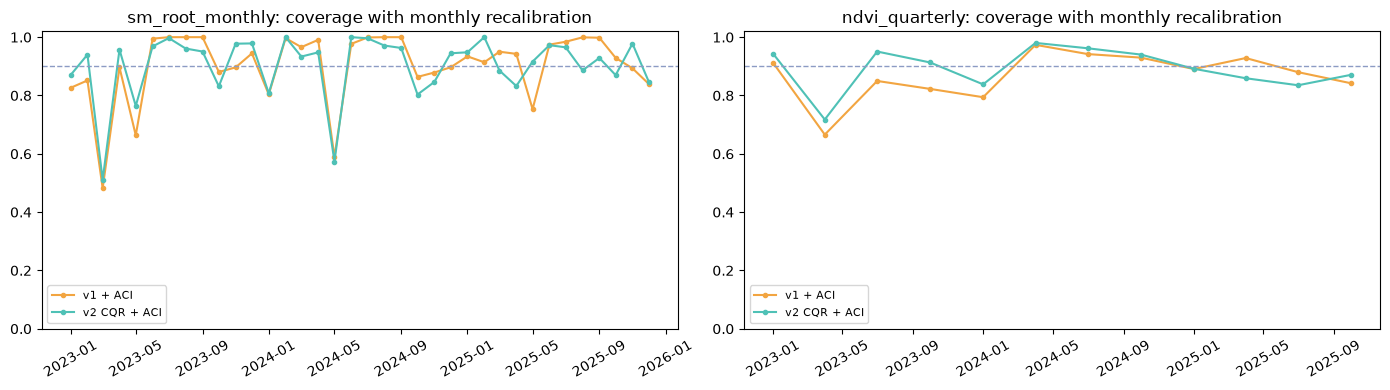

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, n in zip(ax, NAMES):
    for (m, kind), color in [((n, "v1"), "#F2A541"), ((n, "cqr"), "#4FC1B6")]:
        g = ACI[(m, kind)]["run"].groupby("t").inside.mean()
        a.plot(g.index, g.values, color=color, marker="o", ms=3, label=("v1" if kind == "v1" else "v2 CQR") + " + ACI")
    a.axhline(0.9, color="#8C9BC4", ls="--", lw=1); a.set_ylim(0, 1.02); a.legend(fontsize=8); a.tick_params(axis="x", labelrotation=30)
    a.set_title(f"{n}: coverage with monthly recalibration")
plt.tight_layout(); fig.savefig(ART / "v2_aci_coverage.png", dpi=110); plt.show()

## 7. Save (experiment only — the final v1 package is untouched)

In [13]:
for n in NAMES:
    out = ART / n; out.mkdir(exist_ok=True)
    Q[n]["model"].save_model(out / "quantile_model_q05_q95.ubj")
    (out / "cqr_calibration.json").write_text(json.dumps({
        "method": "conformalized quantile regression (Romano et al., 2019): XGBoost quantiles 5% and 95% trained on 1998-2017, "
                  "corrected on Validation 2018-2022", "nominal": NOMINAL, "variant": CAL[n]["variant"],
        "correction_global": CAL[n]["global"], "correction_by_season": CAL[n]["season"], "quantile_trees": Q[n]["trees"],
        "features_in_order": V1[n]["features"], "point_model": "unchanged v1 (artifacts/final_model)",
        "test_2023_2025": RESULT[RESULT.model == n].to_dict("records"),
        "status": "EXPERIMENT. 2023-2025 was already seen by Phase 3; confirm on complete 2026 data before adopting."}, indent=2, default=str))
pd.DataFrame(diag).to_csv(ART / "diagnosis_error_by_period.csv", index=False); HET.to_csv(ART / "diagnosis_error_by_rain.csv", index=False)
pd.DataFrame(SEL).to_csv(ART / "variant_selection_validation.csv", index=False); RESULT.to_csv(ART / "test_2023_2025_comparison.csv", index=False)
pd.DataFrame(BY).to_csv(ART / "test_2023_2025_by_group.csv", index=False); pd.DataFrame(GSEL).to_csv(ART / "aci_gamma_selection_validation.csv", index=False)
(ART / "aci_settings.json").write_text(json.dumps({f"{n}|{k}": {"gamma": a["gamma"], "window_periods": WINDOW[n], "start": "2020-01"} for (n, k), a in ACI.items()}, indent=2))
for f in sorted(ART.rglob("*")):
    if f.is_file(): print(f.relative_to(ML_DIR))

artifacts/v2_intervals_experiment/aci_gamma_selection_validation.csv
artifacts/v2_intervals_experiment/aci_settings.json
artifacts/v2_intervals_experiment/diagnosis_error_by_period.csv
artifacts/v2_intervals_experiment/diagnosis_error_by_rain.csv
artifacts/v2_intervals_experiment/ndvi_quarterly/cqr_calibration.json
artifacts/v2_intervals_experiment/ndvi_quarterly/quantile_model_q05_q95.ubj
artifacts/v2_intervals_experiment/sm_root_monthly/cqr_calibration.json
artifacts/v2_intervals_experiment/sm_root_monthly/quantile_model_q05_q95.ubj
artifacts/v2_intervals_experiment/test_2023_2025_by_group.csv
artifacts/v2_intervals_experiment/test_2023_2025_comparison.csv
artifacts/v2_intervals_experiment/v2_aci_coverage.png
artifacts/v2_intervals_experiment/v2_coverage.png
artifacts/v2_intervals_experiment/variant_selection_validation.csv
